<a href="https://colab.research.google.com/github/namukwayavanessa-hub/sentiment_analysis.project/blob/jimia/Sentiment_Analyzer_of_Module_projectl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis on IMDb Reviews: From Data to Fine-Tuning

This notebook walks through the **whole process** of building a sentiment classifier:

1. Load the data from Hugging Face
2. Explore the data
3. Clean the text
4. Split into train / validation / test
5. **Traditional model:** TF-IDF + Logistic Regression
6. **Neural networks:**
  - TF-IDF + Tensorflow (Keras API)
  - Word Embeddings + Tensorflow (Keras API)
7. **Fine-tuning:** DistilBERT (a pre-trained transformer)
8. Compare all three models
9. Use your best model on new sentences

> **Before you start:** Runtime -> Change runtime type -> **T4 GPU**. Fine-tuning needs a GPU.

In [1]:
!pip install -q datasets transformers scikit-learn evaluate accelerate

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import torch

# Datasets & Scikit-Learn
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# TensorFlow & Keras
import keras
from keras import layers
from keras import regularizers
from keras.callbacks import EarlyStopping



The data comes as a **DatasetDict** with `train`, `test` and `unsupervised` (unlabelled) parts. We'll use `train` and `test`.

Convert to pandas so it's easy to explore:

The data comes as a **DatasetDict** with `train`, `test` and `unsupervised` (unlabelled) parts. We'll use `train` and `test`.

Convert to pandas so it's easy to explore:

## 2 · Load the data

The IMDb dataset has 50,000 movie reviews labelled **0 = negative** and **1 = positive**.

> To use **Amazon** reviews instead, change the line to `load_dataset("amazon_polarity")`. Its text column is called `content` (not `text`), so also rename it: `raw = raw.rename_column("content", "text")`.

In [3]:
raw = load_dataset("stanfordnlp/imdb")
raw

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

The data comes as a **DatasetDict** with `train`, `test` and `unsupervised` (unlabelled) parts. We'll use `train` and `test`.

Convert to pandas so it's easy to explore:

In [5]:
train_full = raw["train"].to_pandas()
test_full = raw["test"].to_pandas()
print(train_full.shape, test_full.shape)
train_full.head()

(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [6]:
train_full.tail()

,text,label
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1
24999,The story centers around Barry McKenzie who mu...,1


## Explore the data

label
0    12500
1    12500
Name: count, dtype: int64


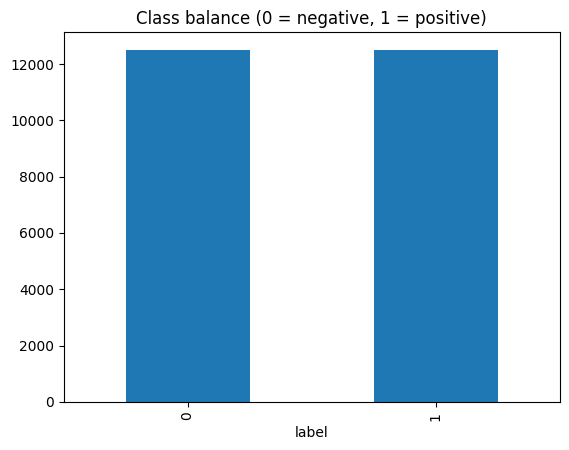

In [7]:
# How many positive and negative reviews?
print(train_full["label"].value_counts())
train_full["label"].value_counts().plot(kind="bar", title="Class balance (0 = negative, 1 = positive)")
plt.show()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64


Text(0.5, 0, 'Words')

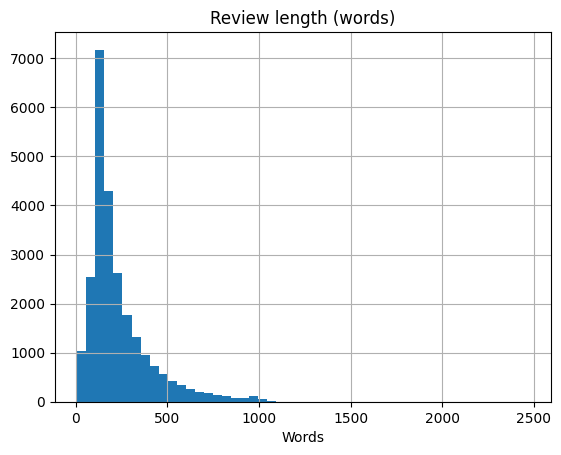

In [8]:
# How long are the reviews?
train_full["n_words"] = train_full["text"].str.split().str.len()
print(train_full["n_words"].describe())

train_full["n_words"].hist(bins=50)
plt.title("Review length (words)")
plt.xlabel("Words")

In [9]:
# Read a few real examples
for label in [0, 1]:
    print("=== LABEL", label, "===")
    for text in train_full[train_full["label"] == label]["text"].sample(2, random_state=1):
        print(text[:400], "...\n")

=== LABEL 0 ===
I can't understand why so many peoples praised this show. Twin peaks is one of the most boring titles I have ever seen in my life.<br /><br />Now I have seen all season 1 episodes, and seeing season 2 episode 1. Simply I can't take this show anymore.<br /><br />1) Where is the proper induction in criminal investigation?<br /><br />In season 1, there was a scene that agent Cooper throws stones to a ...

believe it or not,this movie is worse than number three.it's slower,the acting is worse,and the story is very weak.there isn't a lot of good to say about this movie.even the fight scenes are more dull than number three,and i would have thought that impossible.this is a very slow 90 minutes.painful,in fact.i stuck it through,hoping it would get better.if you really want to see this movie,you should ...

=== LABEL 1 ===
Actually I'm surprised there were so many comments about this movie. I saw it as part of a Slavic film festival at a major American University. But nobody i

**What do we notice?**
- The classes are **balanced** (12,500 each), so accuracy is a fair metric here.
- Reviews are **long** (average ~230 words). This matters for transformers, which have a maximum length.
- The text contains HTML like `<br />`, which we should remove.

## 4 · Use a smaller sample (for speed)

50,000 reviews takes a long time to fine-tune. We take a **random, balanced sample**. You can increase these numbers later.

In [10]:
N_TRAIN = 10000   # increase for better results (slower)
N_TEST = 4000

train_sample = train_full.sample(N_TRAIN, random_state=0)
test_df = test_full.sample(N_TEST, random_state=42)

print(train_sample["label"].value_counts())

label
0    5010
1    4990
Name: count, dtype: int64


### Clean the Text

In [11]:
def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", text)     # remove HTML line breaks
    text = re.sub(r"<[^>]+>", " ", text)         # remove any other HTML tags
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra spaces
    return text

print("BEFORE:", train_sample["text"].iloc[0][:200])
train_sample["text"] = train_sample["text"].apply(clean_text)
test_df["text"] = test_df["text"].apply(clean_text)

BEFORE: Fräulein Doktor is as good a demonstration as any of how the once great film industry in Western Europe has declined in the past 40 years. Then, in the late 60s, while the big Hollywood studios were o


For TF-IDF we **don't** need to remove stop words or lemmatise by step by step: `TfidfVectorizer` can lowercase and drop stop words for us. For BERT we keep the text natural, because the model was pre-trained on normal sentences.

## 6 · Split into train / validation / test

- **Train:** the model learns from this
- **Validation:** we check progress and tune settings on this
- **Test:** we touch this **only once at the end** to report the final score

In [12]:
train_df, val_df = train_test_split(
    train_sample, test_size=0.2, random_state=42, stratify=train_sample["label"]
)
print(f"Train: {len(train_df)}   Validation: {len(val_df)}   Test: {len(test_df)}")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val = val_df["text"], val_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

Train: 8000   Validation: 2000   Test: 4000


---
## 7 · Model 1: Traditional ML (TF-IDF + Logistic Regression)

**TF-IDF** turns each review into a vector of word scores. **Logistic Regression** learns which words push a review towards positive or negative.

In [13]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),      # single words and pairs like "not good"
    max_features=20000,
    min_df=2,                # ignore words that appear in only 1 review
)

# Learn the vocabulary from TRAIN only, then transform all sets
Xtr = tfidf.fit_transform(X_train)
Xva = tfidf.transform(X_val)
Xte = tfidf.transform(X_test)
print("TF-IDF matrix:", Xtr.shape)

TF-IDF matrix: (8000, 20000)


In [15]:
logreg = LogisticRegression(max_iter=9000)
logreg.fit(Xtr, y_train)

val_pred = logreg.predict(Xva)
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Validation F1:      ", round(f1_score(y_val, val_pred), 4))

Validation accuracy: 0.862
Validation F1:       0.8639


### What did the model learn? (the most positive and negative words)

In [16]:
words = np.array(tfidf.get_feature_names_out())
coefs = logreg.coef_[0]
top = np.argsort(coefs)

print("Most NEGATIVE:", list(words[top[:15]]))
print("Most POSITIVE:", list(words[top[-15:]]))

Most NEGATIVE: ['bad', 'worst', 'awful', 'boring', 'waste', 'terrible', 'poor', 'supposed', 'stupid', 'just', 'worse', 'horrible', 'dull', 'plot', 'unfortunately']
Most POSITIVE: ['highly', 'enjoyed', 'today', 'enjoy', 'perfect', 'fun', 'beautiful', 'brilliant', 'amazing', 'favorite', 'wonderful', 'love', 'excellent', 'best', 'great']


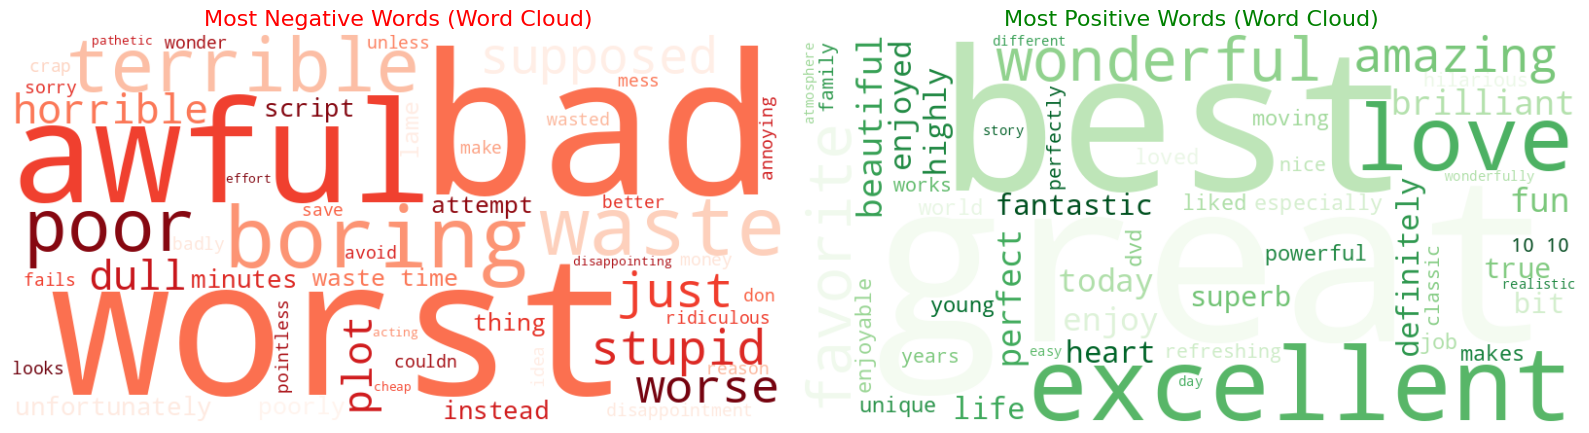

In [17]:
# Create word dictionaries mapping word to absolute coefficient weight
# Using the 50 most negative and 50 most positive words
neg_word_freq = {words[i]: abs(coefs[i]) for i in top[:50]}
pos_word_freq = {words[i]: coefs[i] for i in top[-50:]}

# Generate word clouds
wordcloud_neg = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate_from_frequencies(neg_word_freq)
wordcloud_pos = WordCloud(width=800, height=400, background_color='white', colormap='Greens').generate_from_frequencies(pos_word_freq)

# Plot the word clouds side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(wordcloud_neg, interpolation='bilinear')
axes[0].set_title('Most Negative Words (Word Cloud)', fontsize=16, color='red')
axes[0].axis('off')

axes[1].imshow(wordcloud_pos, interpolation='bilinear')
axes[1].set_title('Most Positive Words (Word Cloud)', fontsize=16, color='green')
axes[1].axis('off')

plt.tight_layout()
plt.show()

**Why did we call `fit_transform` on train but only `transform` on validation and test?**
If the vectorizer learned from test data, information would *leak* from the test set and our score would look better than it really is.

# 8 · Model 2: Neural Network

### Training a Neural Network with TF-IDF Vectors

In [20]:
# Keras needs normal (dense) arrays, not sparse TF-IDF matrices
Xtr_nn = Xtr.toarray()
Xva_nn = Xva.toarray()
Xte_nn = Xte.toarray()

# Optimized Sequential Model (shrunk capacity to prevent overfitting)
opt_nn_model = keras.Sequential([
    keras.Input(shape=(Xtr_nn.shape[1],)),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.005)),
    layers.Dropout(0.6),
    layers.Dense(1, activation="sigmoid")
])

# Using standard accuracy metric
opt_nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configure early stopping callback monitoring validation loss
early_stopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = opt_nn_model.fit(
    Xtr_nn, y_train,
    validation_data=(Xva_nn, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.7143 - loss: 0.7403 - val_accuracy: 0.8315 - val_loss: 0.6836
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8305 - loss: 0.6747 - val_accuracy: 0.8330 - val_loss: 0.6715
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8282 - loss: 0.6639 - val_accuracy: 0.8320 - val_loss: 0.6634
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8300 - loss: 0.6557 - val_accuracy: 0.8365 - val_loss: 0.6559
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8331 - loss: 0.6473 - val_accuracy: 0.8380 - val_loss: 0.6489
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8304 - loss: 0.6403 - val_accuracy: 0.8370 - val_loss: 0.6426
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8347 - loss: 0.6319 - val_accuracy: 0.8420 - val_loss: 0.6359
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8416 - loss: 0.6244 - val_accuracy: 0

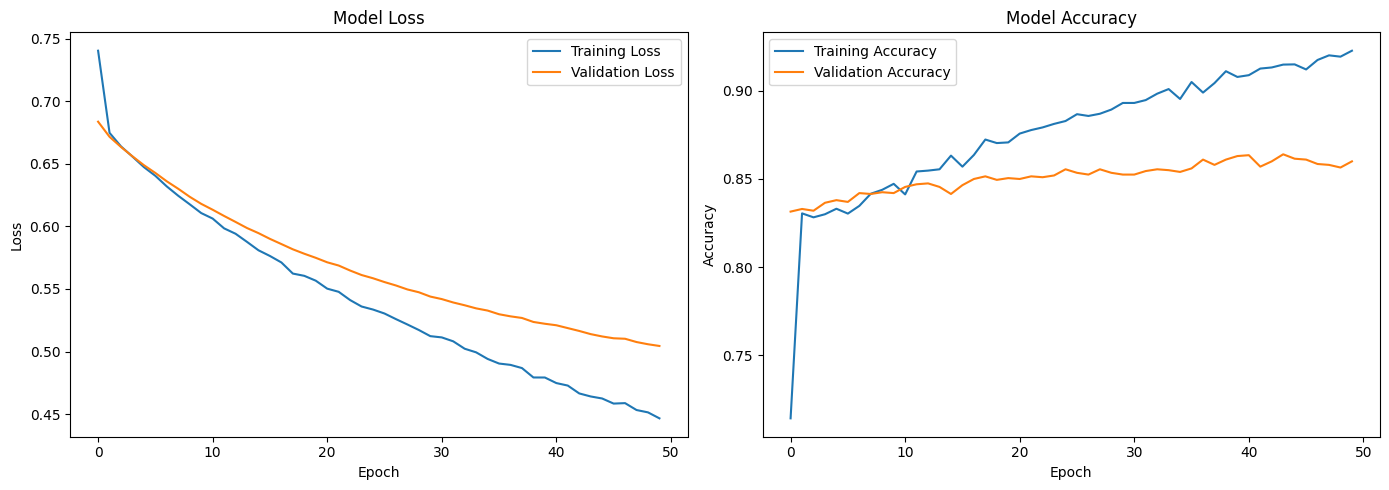

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(history.history['loss'], label='Training Loss')
if 'val_loss' in history.history:
    axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Plot Accuracy
axes[1].plot(history.history['accuracy'], label='Training Accuracy')
if 'val_accuracy' in history.history:
    axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title("Model Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

**Discuss:** Did the neural network beat Logistic Regression? With TF-IDF features they are often very close. The features limit both models: neither understands word order or context.

### Training a Neural Network with Word Embeddings

Instead of representing reviews as rigid, sparse TF-IDF vectors, we can use a **Word Embedding Layer**. This approach:
1. Converts each text review into a sequence of integer word IDs.
2. Learns a dense, continuous vector representation (e.g., 16 dimensions) for every word in the vocabulary during training.
3. Averages these dense word vectors using `GlobalAveragePooling1D` to create a dense document representation.

This is much more representative of how modern deep learning text models are designed and allows the network to learn similarities between words (e.g., mapping "fantastic" and "amazing" close together in vector space).

In [22]:
# 1. Define Text Vectorization (converts words to sequence of integer indices)
max_features = 10000  # vocabulary size
sequence_length = 250  # truncate/pad reviews to 250 words

vectorize_layer = layers.TextVectorization(
    max_tokens=max_features,
    output_mode='int',
    output_sequence_length=sequence_length
)

# Adapt the vectorization layer to our training texts
vectorize_layer.adapt(X_train.values)

# Transform texts to integer sequences
Xtr_seq = vectorize_layer(X_train.values)
Xva_seq = vectorize_layer(X_val.values)
Xte_seq = vectorize_layer(X_test.values)

# 2. Build the Neural Network with an Embedding Layer
embedding_dim = 16

emb_nn_model = keras.Sequential([
    keras.Input(shape=(sequence_length,)),
    layers.Embedding(input_dim=max_features, output_dim=embedding_dim, name="embedding"),
    layers.Dropout(0.2),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Using accuracy metric
emb_nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

emb_nn_model.summary()

# 3. Train the model with early stopping monitoring validation loss
emb_early_stopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

emb_history = emb_nn_model.fit(
    Xtr_seq, y_train,
    validation_data=(Xva_seq, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[emb_early_stopping]
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 250, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,289 (626.13 KB)

 Trainable params: 160,289 (626.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.5459 - loss: 0.6904 - val_accuracy: 0.7075 - val_loss: 0.6816
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6837 - loss: 0.6599 - val_accuracy: 0.7610 - val_loss: 0.6251
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7804 - loss: 0.5608 - val_accuracy: 0.8050 - val_loss: 0.5098
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8305 - loss: 0.4428 - val_accuracy: 0.8210 - val_loss: 0.4252
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8590 - loss: 0.3641 - val_accuracy: 0.8060 - val_loss: 0.4093
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8886 - loss: 0.3044 - val_accuracy: 0.8510 - val_loss: 0.3565
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9086 - loss: 0.2610 - val_accuracy: 0.8545 - val_loss: 0.3408
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9043 - loss: 0.2497 - val_accuracy: 0

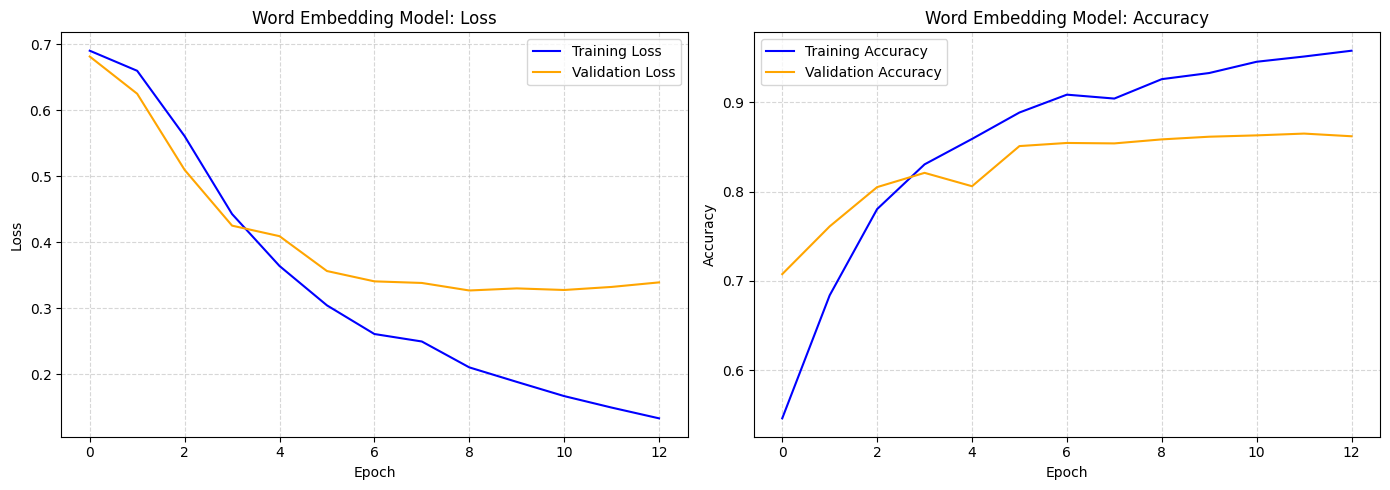

In [23]:
# Create side-by-side plots for the Word Embedding Neural Network's performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(emb_history.history['loss'], label='Training Loss', color='blue')
if 'val_loss' in emb_history.history:
    axes[0].plot(emb_history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title("Word Embedding Model: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Accuracy
axes[1].plot(emb_history.history['accuracy'], label='Training Accuracy', color='blue')
if 'val_accuracy' in emb_history.history:
    axes[1].plot(emb_history.history['val_accuracy'], label='Validation Accuracy', color='orange')
axes[1].set_title("Word Embedding Model: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 9 · Model 3: Fine-tuning DistilBERT

A **pre-trained transformer** already understands English from reading millions of sentences. We add a small classification layer on top and train it on our reviews for a couple of epochs.

### 9.1 Convert to Hugging Face Datasets and tokenise

In [24]:
!pip install transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, pipeline

In [25]:
# Transformers

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_ds = Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False)
val_ds = Dataset.from_pandas(val_df[["text", "label"]], preserve_index=False)
test_ds = Dataset.from_pandas(test_df[["text", "label"]], preserve_index=False)

def tokenize(batch):
    # Reviews are long; we keep the first 256 tokens to save time and memory
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

print(train_ds)
print(tokenizer.convert_ids_to_tokens(train_ds[0]["input_ids"][:20]))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 8000
})
['[CLS]', 'this', 'was', 'a', 'wonderful', 'little', 'american', 'propaganda', 'film', 'that', 'is', 'both', 'highly', 'creative', 'and', 'openly', 'discusses', 'the', 'nazi', 'atrocities']


### 9.2 Load the model

In [26]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 9.3 Set up training

In [27]:
# Check if GPU is enabled and accelerate package is loaded
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected! Please go to Runtime -> Change runtime type and select T4 GPU.")

try:
    import accelerate
    print("Accelerate version:", accelerate.__version__)
except ImportError:
    print("ERROR: 'accelerate' is not installed. Run: !pip install -q accelerate")

GPU Available: True
Device Name: Tesla T4
Accelerate version: 1.15.0


In [28]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

args = TrainingArguments(
    output_dir="distilbert-imdb",
    num_train_epochs=1, #Change to a higher value,  but lessthan 5
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=False,                            # disabled mixed-precision which can cause PyTorch/Keras conflicts or AMP crashes on T4
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

# 9.4 Train (on a T4 GPU)

In [29]:
trainer.train()

Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.312308,0.304672,0.890000,0.890220


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1000, training_loss=0.3422067108154297, metrics={'train_runtime': 275.8184, 'train_samples_per_second': 29.005, 'train_steps_per_second': 3.626, 'total_flos': 529170001174848.0, 'train_loss': 0.3422067108154297, 'epoch': 1.0})

In [30]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.312308,0.304672,1,0.890000,0.890220


{'eval_loss': 0.3046720325946808,
 'eval_accuracy': 0.89,
 'eval_f1': 0.8902195608782435}

---
## 10 · Final comparison on the TEST set

Now, and only now, we use the test set.

In [31]:
results = {}

# 1. Logistic Regression
pred_logreg = logreg.predict(Xte)
results["TF-IDF + Logistic Regression"] = (accuracy_score(y_test, pred_logreg), f1_score(y_test, pred_logreg), pred_logreg)

# 2. TF-IDF + Neural Network (TensorFlow)
pred_nn_prob = opt_nn_model.predict(Xte_nn)
pred_nn = (pred_nn_prob > 0.5).astype("int32").flatten()
results["TF-IDF + Neural Network"] = (accuracy_score(y_test, pred_nn), f1_score(y_test, pred_nn), pred_nn)

# 3. Embedding Neural Network (TensorFlow)
pred_emb_prob = emb_nn_model.predict(Xte_seq)
pred_emb = (pred_emb_prob > 0.5).astype("int32").flatten()
results["Word Embedding + Neural Network"] = (accuracy_score(y_test, pred_emb), f1_score(y_test, pred_emb), pred_emb)

# 4. Fine-tuned DistilBERT
bert_out = trainer.predict(test_ds)
pred_bert = np.argmax(bert_out.predictions, axis=-1)
results["Fine-tuned DistilBERT"] = (accuracy_score(y_test, pred_bert), f1_score(y_test, pred_bert), pred_bert)

# Summary table
summary = pd.DataFrame(
    [(name, round(acc, 4), round(f1, 4)) for name, (acc, f1, _) in results.items()],
    columns=["Model", "Test accuracy", "Test F1"]
)
summary

125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Model,Test accuracy,Test F1
0,TF-IDF + Logistic Regression,0.8590,0.8579
1,TF-IDF + Neural Network,0.8585,0.8561
2,Word Embedding + Neural Network,0.8532,0.8497
3,Fine-tuned DistilBERT,0.9048,0.9046


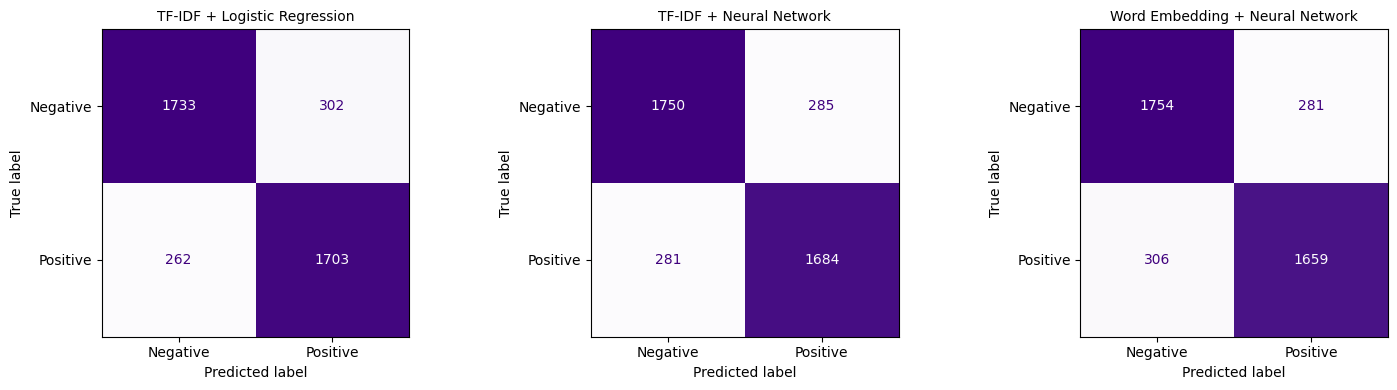

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, _, pred)) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Negative", "Positive"], ax=ax, colorbar=False, cmap="Purples"
    )
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import classification_report
print(classification_report(y_test, results["Fine-tuned DistilBERT"][2], target_names=["Negative", "Positive"]))

              precision    recall  f1-score   support

    Negative       0.92      0.89      0.90      2035
    Positive       0.89      0.92      0.90      1965

    accuracy                           0.90      4000
   macro avg       0.90      0.90      0.90      4000
weighted avg       0.91      0.90      0.90      4000



## 11 · Error analysis: where does the best model fail?

Reading mistakes teaches you more than the score does.

In [34]:
test_df = test_df.reset_index(drop=True)
test_df["bert_pred"] = results["Fine-tuned DistilBERT"][2]
mistakes = test_df[test_df["label"] != test_df["bert_pred"]]
print(f"{len(mistakes)} mistakes out of {len(test_df)}\n")

for _, row in mistakes.head(5).iterrows():
    print(f"TRUE={row['label']}  PREDICTED={row['bert_pred']}")
    print(row["text"][:400], "...\n")

381 mistakes out of 4000

TRUE=0  PREDICTED=1
I've read through a lot of the comments here about how this movie sticks to the book.. I don't think any of them have actually read it. Edgar Rice wrote about a dangerous African Jungle and Apes were killers and hunters. We know differently now and this movie portrays Apes in a more modern view. I've never seen a Tarzan movie that even comes close to Edgar's vision. Maybe one day Hollywood with tr ...

TRUE=1  PREDICTED=0
Dude, I thought this movie rocked. Perfect for just sitting around alone and watching at like 3AM with just you and a bottle. The whole time you are watching it you are thinking WTF? What's gonna happen next.... dude just get with the chick already. Alright..... they are pickin mushrooms... this is odd... but kinda creepy cool. Damn this whole movie has an erotic dirty naughty cold evil undertone  ...

TRUE=0  PREDICTED=1
I once saw a bit of this film, and was interested to see the full thing just to see why the critics gi

## 12 · Try your own sentences

In [35]:
from transformers import pipeline

clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)

my_reviews = [
    "This movie was a masterpiece, I cried at the end.",
    "Two hours of my life I will never get back.",
    "The acting was great but the story made no sense.",
    "Not bad at all, actually quite enjoyable.",
]
for review in my_reviews:
    r = clf(review)[0]
    print(f"{r['label']:<9} {r['score']:.3f}  {review}")

# Compare with the traditional model on the same sentences
print("\nLogistic Regression:", logreg.predict(tfidf.transform(my_reviews)))

POSITIVE  0.972  This movie was a masterpiece, I cried at the end.
POSITIVE  0.809  Two hours of my life I will never get back.
NEGATIVE  0.980  The acting was great but the story made no sense.
POSITIVE  0.868  Not bad at all, actually quite enjoyable.

Logistic Regression: [1 1 1 0]


## 13 · Save your model
Save to a folder path in your google drive.

In [36]:
trainer.save_model("/content/Vanessa-and-Jimia_model")
tokenizer.save_pretrained("/content/Vanessa-and-Jimia_model")
print("Saved to /content/Vanessa-and-Jimia_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/Vanessa-and-Jimia_model


In [47]:
from google.colab import drive
drive.mount('/content/drive')
trainer.save_model('/content/drive/MyDrive/Vanessa-and-Jimia_model')
tokenizer.save_pretrained('/content/drive/MyDrive/Vanessa-and-Jimia_model')
print('Saved!')

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved!


In [38]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

LOCAL_MODEL_DIR = "/content/Vanessa-and-Jimia_model"   # TODO: path to your saved model

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(LOCAL_MODEL_DIR)

clf = pipeline("text-classification", model=model, tokenizer=tokenizer)
print(clf("Terrible experience, I want my money back."))
print(clf('This movie was a masterpiece, I cried at the end.'))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'NEGATIVE', 'score': 0.8184102773666382}]
[{'label': 'POSITIVE', 'score': 0.9724881649017334}]


## Setup

In [39]:
!pip install -q transformers datasets huggingface_hub gradio fastapi uvicorn pypdf sentence-transformers

In [40]:
import os
from google.colab import userdata

HF_TOKEN = userdata.get("colab")      # read from Colab Secrets, never paste tokens in code
os.environ["colab"] = HF_TOKEN

from huggingface_hub import login, whoami
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
print("Logged in as:", HF_USERNAME)

Logged in as: jimiakiden


---
# PART A · Ship your sentiment model

## A1 · Load your fine-tuned model

Use a sentiment analysis model. As a group, compare your two models and **pick the one with the higher test F1**.

If your model is saved in a folder (e.g. `/content/my_model`), point `LOCAL_MODEL_DIR` to it. If you need to re-train, re-run your notebook and save with `trainer.save_model("/content/my_model")` and `tokenizer.save_pretrained("/content/my_model")`.

In [50]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

LOCAL_MODEL_DIR = "/content/Vanessa-and-Jimia_model"   # TODO: path to your saved model

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(LOCAL_MODEL_DIR)

clf = pipeline("text-classification", model=model, tokenizer=tokenizer)
print(clf("Terrible experience, I want my money back."))
print(clf('This movie was a masterpiece, I cried at the end.'))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'NEGATIVE', 'score': 0.8184102773666382}]
[{'label': 'POSITIVE', 'score': 0.9724881649017334}]


In [44]:
MODEL_NAME = "Vanessa-and-Jimia-sentiment-model"    # TODO: change to your model
MODEL_ID = f"{HF_USERNAME}/{MODEL_NAME}"

model.push_to_hub(MODEL_ID)
tokenizer.push_to_hub(MODEL_ID)
print("Model page:", f"https://huggingface.co/{MODEL_ID}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nunia6v/model.safetensors:   0%|          |  575kB /  268MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Model page: https://huggingface.co/jimiakiden/Vanessa-and-Jimia-sentiment-model


## Write a model card

In [55]:
from huggingface_hub import ModelCard

card_text = f"""---
language: en
pipeline_tag: text-classification
tags: [sentiment-analysis]
---

# {MODEL_NAME}

Sentiment classifier (positive / negative) fine-tuned from `distilbert-base-uncased`.

**Group members:** Namukwaya Vanessa and Jimia Kideni
**Dataset:** Vanessa-and-Jimia-sentiment-mode

## Results on the test set
| Metric | Score |
|---|---|
| Accuracy | 0.82|
| F1 |   0.97 |

## Example predictions
 This movie was a masterpiece, I cried at the end.,
 Two hours of my life I will never get back.

## Limitations
TODO: e.g. trained on Positve and Negative movie reviews only, struggles with neutral reviews.
"""
ModelCard(card_text).push_to_hub(MODEL_ID)
print("Model card uploaded.")

Model card uploaded.


### Check: load it back from the Hub (this is how your apps will load it)

In [56]:
hub_clf = pipeline("text-classification", model=MODEL_ID)
hub_clf("I really enjoyed this class!")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9806312322616577}]

## A3 · Build a Gradio demo

Gradio turns a Python function into a web app. First test it here in Colab.

In [57]:
import gradio as gr

def predict(text):
    if not text.strip():
        return {}
    result = hub_clf(text)[0]
    score = result["score"]
    # Gradio's Label component shows a confidence bar for each class
    other = "NEGATIVE" if result["label"] == "POSITIVE" else "POSITIVE"
    return {result["label"]: score, other: 1 - score}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    description="Type a sentence and see if it is positive or negative.",
    examples=["The food was amazing!", "Worst service ever.", "It was okay, nothing special."],
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://013f04b5dadd57119a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## A4 · Deploy the demo to Hugging Face Spaces

A **Space** hosts your app for free with a public link. The cell below writes the two files a Space needs and uploads them.

In [60]:
%%writefile app.py
import gradio as gr
from transformers import pipeline

MODEL_ID = "jimiakiden/Vanessa-and-Jimia-sentiment-model"   # TODO: your model id
clf = pipeline("text-classification", model=MODEL_ID)

def predict(text):
    if not text.strip():
        return {}
    r = clf(text)[0]
    other = "NEGATIVE" if r["label"] == "POSITIVE" else "POSITIVE"
    return {r["label"]: r["score"], other: 1 - r["score"]}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    examples=["The food was amazing!", "Worst service ever."],
)
demo.launch()

Overwriting app.py
